# Decisions and Uncertainty

In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

In [2]:
# polars
import polars as pl
from IPython.display import display
import numpy as np

def _append(base, extra):
    """Append a value or a Series onto a Series."""
    extra_s = extra if isinstance(extra, pl.Series) else pl.Series([extra])
    if base.len() == 0:
        return extra_s
    if base.dtype != extra_s.dtype:
        try:
            extra_s = extra_s.cast(base.dtype, strict=False)
        except Exception:
            base = base.cast(extra_s.dtype, strict=False)
    return pl.concat([base, extra_s])

def sample_proportions_pl(sample_size, proportions):
    """Draw `sample_size` items from `proportions` and return each category's share.

    A category that is not drawn stays 0. Polars `sample` has no weights, so the
    draw uses `np.random.choice`.
    """
    proportions = list(proportions)
    categories = list(range(len(proportions)))
    drawn = np.random.choice(categories, size=sample_size, p=proportions)
    counts = pl.Series("drawn", drawn).value_counts()
    count_dict = dict(zip(counts["drawn"].to_list(), counts["count"].to_list()))
    return [count_dict.get(cat, 0) / sample_size for cat in categories]


## Comparing Distributions: Be the Jury Program

In [3]:
# datascience
# Counts are from the 88% of participants in Be the Jury in 2023 who completed the exit survey and shared their race

sf = Table().with_columns(
    'Race/Ethnicity',
    ['American Indian or Alaska Native',
     'Asian',
     'Black or African American',
     'Hispanic or Latino',
     'Native Hawaiian or Other Pacific Islander',
     'Some Other Race',
     'White'],
    'Count',[4, 168,23,59,4,5,175],
    'SF Census (2020)', [0.005, 0.3440, 0.0520, 0.1540, 0.0040, 0.0490, 0.3920])
sf.set_format(2, PercentFormatter)

Race/Ethnicity,Count,SF Census (2020)
American Indian or Alaska Native,4,0.50%
Asian,168,34.40%
Black or African American,23,5.20%
Hispanic or Latino,59,15.40%
Native Hawaiian or Other Pacific Islander,4,0.40%
Some Other Race,5,4.90%
White,175,39.20%


In [4]:
# polars
# Counts are from the 88% of participants in Be the Jury in 2023 who completed the exit survey and shared their race

sf_pl = pl.DataFrame({'Race/Ethnicity': ['American Indian or Alaska Native',
     'Asian',
     'Black or African American',
     'Hispanic or Latino',
     'Native Hawaiian or Other Pacific Islander',
     'Some Other Race',
     'White'], 'Count': [4, 168,23,59,4,5,175], 'SF Census (2020)': [0.005, 0.3440, 0.0520, 0.1540, 0.0040, 0.0490, 0.3920]})
sf_pl

Race/Ethnicity,Count,SF Census (2020)
str,i64,f64
"""American Indian or Alaska Nati…",4,0.005
"""Asian""",168,0.344
"""Black or African American""",23,0.052
"""Hispanic or Latino""",59,0.154
"""Native Hawaiian or Other Pacif…",4,0.004
"""Some Other Race""",5,0.049
"""White""",175,0.392


In [5]:
# datascience
sum(sf.column('Count'))

438

In [6]:
# polars
sum(sf_pl.get_column('Count'))

438

In [7]:
# datascience
sf = (sf.with_column('Panels', sf.column('Count') / sum(sf.column('Count')))
        .relabeled('SF Census (2020)', 'Eligible'))
sf.set_format(3, PercentFormatter)

Race/Ethnicity,Count,Eligible,Panels
American Indian or Alaska Native,4,0.50%,0.91%
Asian,168,34.40%,38.36%
Black or African American,23,5.20%,5.25%
Hispanic or Latino,59,15.40%,13.47%
Native Hawaiian or Other Pacific Islander,4,0.40%,0.91%
Some Other Race,5,4.90%,1.14%
White,175,39.20%,39.95%


In [8]:
# polars
sf_pl = (sf_pl.with_columns(pl.Series('Panels', sf_pl.get_column('Count') / sum(sf_pl.get_column('Count')))).rename({'SF Census (2020)': 'Eligible'}))
sf_pl

Race/Ethnicity,Count,Eligible,Panels
str,i64,f64,f64
"""American Indian or Alaska Nati…",4,0.005,0.009132
"""Asian""",168,0.344,0.383562
"""Black or African American""",23,0.052,0.052511
"""Hispanic or Latino""",59,0.154,0.134703
"""Native Hawaiian or Other Pacif…",4,0.004,0.009132
"""Some Other Race""",5,0.049,0.011416
"""White""",175,0.392,0.399543


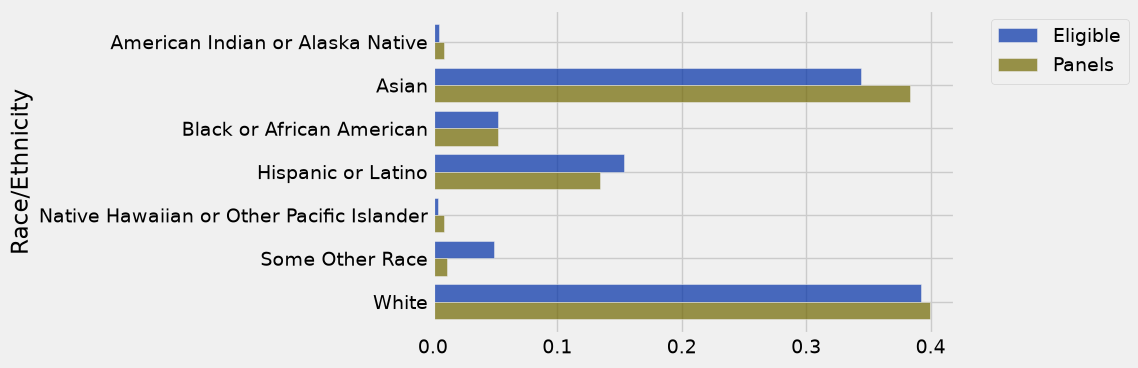

In [9]:
# datascience
sf.select(0, 2, 3).barh(0)

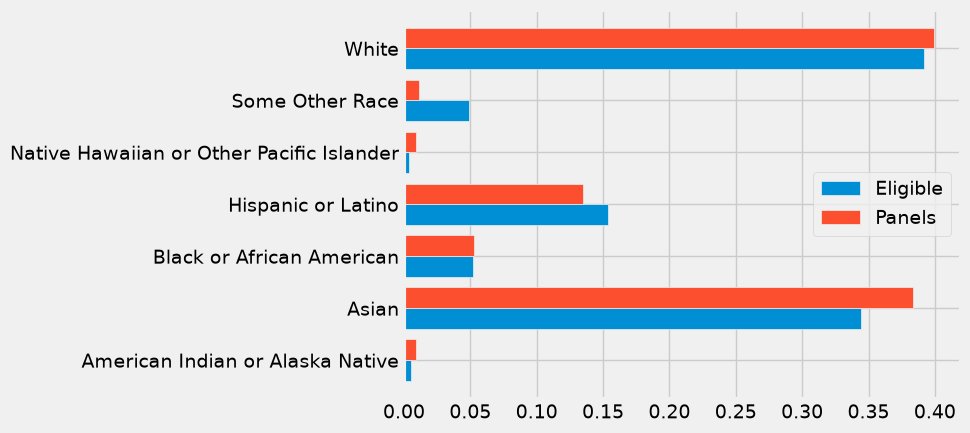

In [10]:
# polars
# matplotlib
_df = sf_pl.select(pl.nth(0), pl.nth(2), pl.nth(3))
_cat = _df.columns[0]
_vals = [c for c in _df.columns if c != _cat and _df[c].dtype.is_numeric()]
if len(_vals) == 1:
    plots.barh(_df.get_column(_cat).to_list(), _df.get_column(_vals[0]).to_list())
    plots.xlabel(_vals[0])
else:
    _n = len(_vals)
    _y = list(range(_df.height))
    _h = 0.8 / _n
    for _i, _c in enumerate(_vals):
        plots.barh([y + _i * _h for y in _y], _df.get_column(_c).to_list(), height=_h, label=_c)
    plots.yticks([y + _h * (_n - 1) / 2 for y in _y], _df.get_column(_cat).to_list())
    plots.legend()

In [11]:
# datascience
def tvd(dist1, dist2):
    return sum(abs(dist1 - dist2))/2

jury = sf
model = jury.column('Eligible')
obsvd_tvd = tvd(jury.column('Panels'), model)
obsvd_tvd

0.056881278538812786

In [12]:
# polars
def tvd_pl(dist1, dist2):
    return sum(abs(dist1 - dist2))/2

jury_pl = sf_pl
model_pl = jury_pl.get_column('Eligible')
obsvd_tvd_pl = tvd_pl(jury_pl.get_column('Panels'), model_pl)
obsvd_tvd_pl

0.056881278538812786

In [13]:
# datascience
model = jury.column('Eligible')

def simulated_tvd():
    return tvd(sample_proportions(438, model), model)

tvds = make_array()

num_simulations = 10000
for i in np.arange(num_simulations):
    new_tvd = simulated_tvd()
    tvds = np.append(tvds, new_tvd)

In [14]:
#polars_with_ss_imported
from datascience import sample_proportions
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
model_pl = jury_pl.get_column('Eligible')

def simulated_tvd_pl():
    return tvd_pl(pl.Series("draw", sample_proportions(438, list(model_pl))), model_pl)

tvds_pl = []

num_simulations_pl = 10000
for i in pl.int_range(num_simulations_pl, eager=True):
    new_tvd = simulated_tvd_pl()
    tvds_pl.append(new_tvd)
tvds_pl = pl.Series("values", tvds_pl)

In [15]:
#polars-with-helper
# POLARS_CHANGE: sample_proportions returns an array; store it as a Series
model_pl = jury_pl.get_column('Eligible')

def simulated_tvd_pl():
    return tvd_pl(pl.Series("draw", sample_proportions_pl(438, list(model_pl))), model_pl)

tvds_pl = []

num_simulations_pl = 10000
for i in pl.int_range(num_simulations_pl, eager=True):
    new_tvd = simulated_tvd_pl()
    tvds_pl.append(new_tvd)
tvds_pl = pl.Series("values", tvds_pl)

Observed TVD: 0.0568812785388


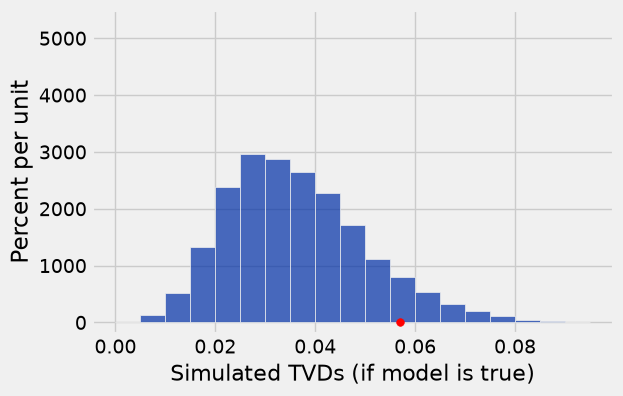

In [16]:
# datascience
title = 'Simulated TVDs (if model is true)'
bins = np.arange(0, .1, .005)

Table().with_column(title, tvds).hist(bins = bins)
print('Observed TVD: ' + str(obsvd_tvd))

# Plotting details; ignore this code
plots.ylim(-2, 55)
plots.scatter(obsvd_tvd, 0, color='red', s=30);

Observed TVD: 0.056881278538812786


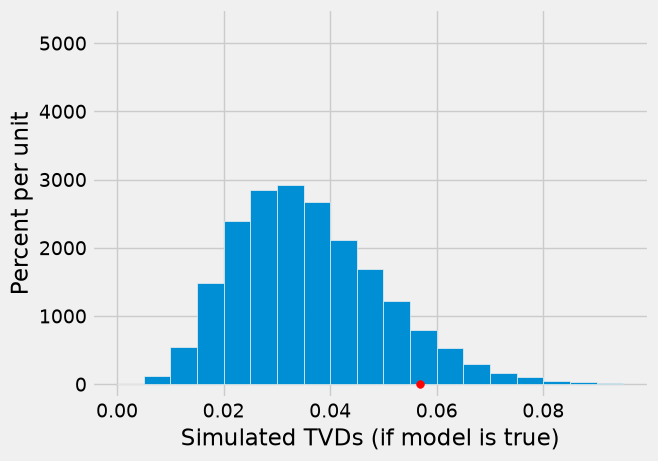

In [17]:
# polars
# matplotlib
title_pl = 'Simulated TVDs (if model is true)'
bins_pl = pl.linear_space(0.0, 0.095, 20, closed="both", eager=True)

_df = pl.DataFrame({title_pl: tvds_pl})
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(bins_pl))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(bins_pl))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))
print('Observed TVD: ' + str(obsvd_tvd_pl))

# Plotting details; ignore this code
plots.ylim(-2, 55)
plots.scatter(obsvd_tvd_pl, 0, color='red', s=30);

**DISCUSS**: Comparing distributions
1. What are the two viewpoints compared above?
    * Null hypothesis: _______.
    * Alternative hypothesis: ________.
1. Why did we choose total variation distance (TVD) as our statistic?
1. Is the observed TVD consistent with the model presented in the null hypothesis?
1. Bonus: Why does TVD have a factor of 2?

## The GSI's Defense ##

In [18]:
# datascience
scores = Table.read_table('scores_by_section.csv')
scores.show(10)

Section,Midterm
1,22
2,12
2,23
2,14
1,20
3,25
4,19
1,24
5,8
6,14


In [19]:
# polars
scores_pl = pl.read_csv('scores_by_section.csv', eol_char='\r')
scores_pl.head(10)

Section,Midterm
i64,i64
1,22
2,12
2,23
2,14
1,20
3,25
4,19
1,24
5,8


In [20]:
# datascience
max(scores.column('Midterm'))

25

In [21]:
# polars
max(scores_pl.get_column('Midterm'))

25

In [22]:
# datascience
min(scores.column('Midterm'))

0

In [23]:
# polars
min(scores_pl.get_column('Midterm'))

0

In [24]:
# datascience
scores.group('Section')

Section,count
1,32
2,32
3,27
4,30
5,33
6,32
7,24
8,29
9,30
10,34


In [25]:
# polars
(lambda _df, _k='Section': _df.group_by(_k).len(name='count').sort(_k))(scores_pl)

Section,count
i64,u32
1,32
2,32
3,27
4,30
5,33
…,…
8,29
9,30
10,34


In [26]:
# datascience
scores.group('Section', np.average).show()

Section,Midterm average
1,15.5938
2,15.125
3,13.6667
4,14.7667
5,17.4545
6,15.0312
7,16.625
8,16.3103
9,14.5667
10,15.2353


In [27]:
# polars
with pl.Config(tbl_rows=-1):
    display((lambda _df, _k='Section': _df.group_by(_k).agg([pl.col(c).mean().alias(f"{c} average") for c in _df.columns if c != _k and _df[c].dtype.is_numeric()]).sort(_k))(scores_pl))

Section,Midterm average
i64,f64
1,15.59375
2,15.125
3,13.666667
4,14.766667
5,17.454545
…,…
8,16.310345
9,14.566667
10,15.235294


## Define the null hypothesis and alternative hypothesis 

See slides

## Choose a test statistic

**DISCUSS**: What test statistic should we use?

<br/><br/><br/>

In [28]:
# datascience
# test statistic: ___________
observed_average = scores.group('Section', np.average).where('Section', 3).column(1).item(0)
observed_average

13.666666666666666

In [29]:
# polars
# test statistic: ___________
observed_average_pl = (lambda _df, _k='Section': _df.group_by(_k).agg([pl.col(c).mean().alias(f"{c} average") for c in _df.columns if c != _k and _df[c].dtype.is_numeric()]).sort(_k))(scores_pl).filter(pl.col('Section') == 3).to_series(1).item(0)
observed_average_pl

13.666666666666666

Conducting a hypothesis test will help us __________

## Find the empirical distribution of the statistic under the null hypothesis

The two viewpoints, restated slightly:

* Null hypothesis: The midterm scores for section 3 are like a random draw of _______ students from the course
* Alternative hypothesis: The midterm scores for section 3 are too low to be explained well by randomness alone.

In [30]:
# datascience
# (1) Simulate what section 3 could have looked like under the null hypothesis,
# i.e., under the hypothesis that the section is like a random sample from the class

random_sample = scores.sample(..., with_replacement=False)
random_sample

TypeError: int() argument must be a string, a bytes-like object or a real number, not 'ellipsis'

In [31]:
# polars
# (1) Simulate what section 3 could have looked like under the null hypothesis,
# i.e., under the hypothesis that the section is like a random sample from the class

random_sample_pl = (scores_pl).sample(n=..., with_replacement=False, shuffle=True)
random_sample_pl

ComputeError: cannot cast 'Object' type

In [32]:
# datascience
# (2) Compute the *test statistic* for this simulated sample
np.average(random_sample.column('Midterm'))

NameError: name 'random_sample' is not defined

In [33]:
# polars
# (2) Compute the *test statistic* for this simulated sample
(random_sample_pl.get_column('Midterm')).mean()

NameError: name 'random_sample_pl' is not defined

In [34]:
# datascience
# (3) Write a function that combines steps (1) and (2)

def random_sample_midterm_avg():
    """
    Simulates one value of the test statistic 
    under the hypothesis that the section is like a random sample from the class
    """
    random_sample = scores.sample(27, with_replacement = False)
    return np.average(random_sample.column('Midterm'))

In [35]:
# polars
# (3) Write a function that combines steps (1) and (2)

def random_sample_midterm_avg_pl():
    """
    Simulates one value of the test statistic 
    under the hypothesis that the section is like a random sample from the class
    """
    random_sample_pl = (scores_pl).sample(n=27, with_replacement=False, shuffle=True)
    return (random_sample_pl.get_column('Midterm')).mean()

In [36]:
# datascience
# (4) Simulate 100,000 copies of the test statistic

sample_averages = make_array()

for i in np.arange(100000):
    sample_averages = np.append(sample_averages, random_sample_midterm_avg())    

In [37]:
# polars
# (4) Simulate 100,000 copies of the test statistic

sample_averages_pl = []

for i in pl.int_range(100000, eager=True):
    sample_averages_pl.append(random_sample_midterm_avg_pl())
sample_averages_pl = pl.Series("values", sample_averages_pl)

**DISCUSS**:
1. Why did we sample **without** replacement?
1. Why did we simulate 100,000 times? Why not 27 times?

## Our Decision

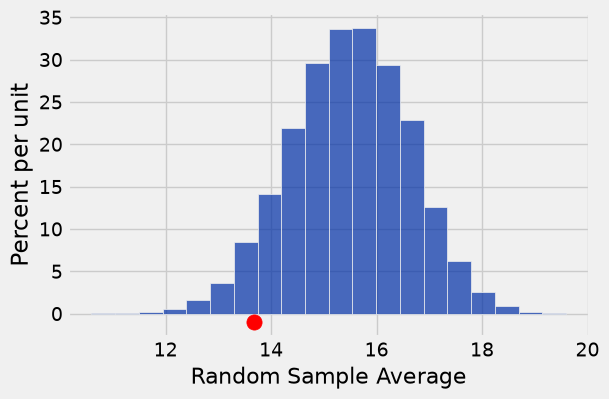

In [38]:
# datascience
# Compare the simulated distribution of the statistic
# and the actual observed statistic
averages_tbl = Table().with_column('Random Sample Average', sample_averages)
averages_tbl.hist(bins = 20)
plots.scatter(observed_average, -0.01, color='red', s=120);

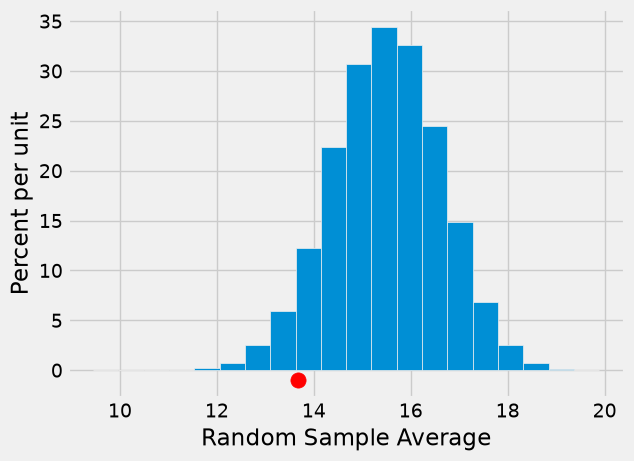

In [39]:
# polars
# matplotlib
# Compare the simulated distribution of the statistic
# and the actual observed statistic
averages_tbl_pl = pl.DataFrame({'Random Sample Average': sample_averages_pl})
_df = averages_tbl_pl
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(20))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(20))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))
plots.scatter(observed_average_pl, -0.01, color='red', s=120);

### Approach 1: Compute the p-value

In [40]:
# datascience
# (1) Calculate the p-value: simulation area beyond observed value
np.count_nonzero(sample_averages <= observed_average) / len(sample_averages)
# (2) See if this is less than the threshold, 5%

0.05713

In [41]:
# polars
# (1) Calculate the p-value: simulation area beyond observed value
(lambda _s: _s.sum() if _s.dtype == pl.Boolean else (_s != 0).sum())(sample_averages_pl <= observed_average_pl) / len(sample_averages_pl)
# (2) See if this is less than the threshold, 5%

0.0569

### Approach 2: Compute the threshold

In [42]:
# datascience
# (1) Find simulated value corresponding to 5% of simulated values
five_percent_point = averages_tbl.sort(0).column(0).item(round(len(sample_averages) * 0.05))
five_percent_point

13.592592592592593

In [43]:
# polars
# (1) Find simulated value corresponding to 5% of simulated values
five_percent_point_pl = averages_tbl_pl.sort(pl.nth(0)).to_series(0).item(round(len(sample_averages_pl) * 0.05))
five_percent_point_pl

13.62962962962963

In [44]:
# datascience
# (2) See if this value is greater than observed value
observed_average

13.666666666666666

In [45]:
# polars
# (2) See if this value is greater than observed value
observed_average_pl

13.666666666666666

### Visual Representation

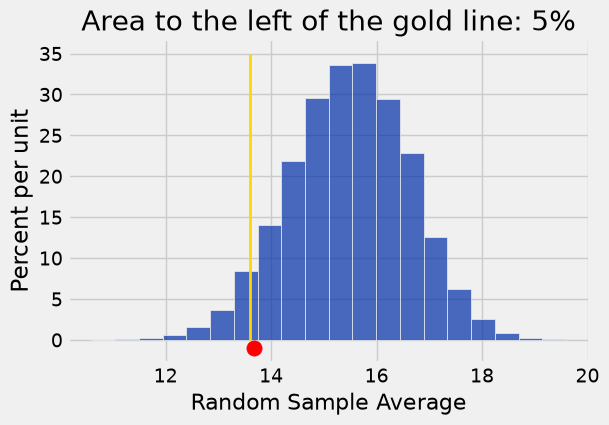

In [46]:
# datascience
averages_tbl.hist(bins = 20)
plots.plot([five_percent_point, five_percent_point], [0, 0.35], color='gold', lw=2)
plots.title('Area to the left of the gold line: 5%');
plots.scatter(observed_average, -0.01, color='red', s=120);

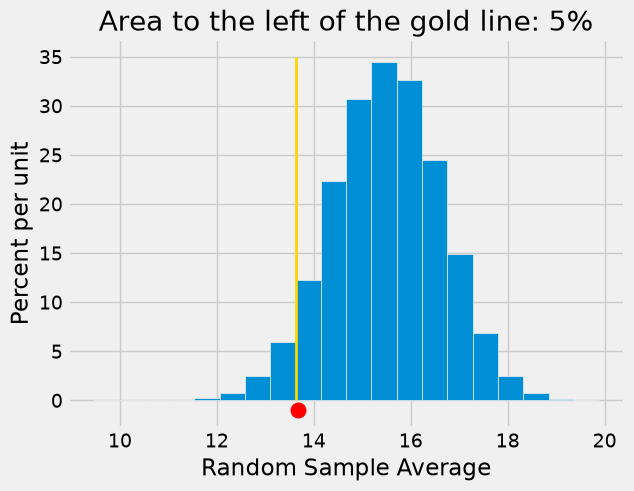

In [47]:
# polars
# matplotlib
_df = averages_tbl_pl
_cols = [c for c in _df.columns if _df[c].dtype.is_numeric()]
if len(_cols) == 1:
    plots.hist(_df.get_column(_cols[0]).to_numpy(), density=True, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(20))
    plots.xlabel(_cols[0])
else:
    for _col in _cols:
        plots.hist(_df.get_column(_col).to_numpy(), density=True, label=_col, bins=(lambda _b: _b.to_numpy() if hasattr(_b, 'to_numpy') else _b)(20))
    plots.legend()
plots.ylabel("Percent per unit")
plots.gca().yaxis.set_major_formatter(lambda x, pos: "{:g}".format(100 * x))
plots.plot([five_percent_point_pl, five_percent_point_pl], [0, 0.35], color='gold', lw=2)
plots.title('Area to the left of the gold line: 5%');
plots.scatter(observed_average_pl, -0.01, color='red', s=120);